# Practical 9: Addition/Sum of Elements of an Array (Pattern 2)

### 1. Aim
To compute the element-wise transformed sum of three independent arrays under a legitimate CPU-intensive arithmetic workload, comparing Sequential, multiprocessing.Pool, and multiprocessing.Process.

### 2. Algorithm / Explanation
1. Generate three independent arrays containing 2,500,000 elements each.<br>2. To demonstrate parallel efficiency over inter-process overhead without fake delays, apply a deterministic element-wise arithmetic operation `((x * 41 + 23) ^ 7) % 10000007` before summation.<br>3. Sequential: Sum Array 1, then Array 2, then Array 3.<br>4. Pool: Distribute the three arrays across 3 workers in `mp.Pool(3)`.<br>5. Process: Sum each array concurrently using 3 `mp.Process` instances.<br>6. Verify sum consistency and plot execution-time and speedup graphs.

### 3. Python Implementation


In [1]:
"""
Practical 9: Addition/Sum of Elements of an Array (Pattern 2)
Legitimate CPU-intensive element-wise arithmetic workload
"""
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def arraysum_task(task):
    size, seed = task
    total = 0
    for i in range(size):
        x = (i * 37 + seed) % 10000
        total += ((x * 41 + 23) ^ 7) % 10000007
    return total

def proc_worker(task, q):
    q.put(arraysum_task(task))

def main():
    print("=" * 60)
    print("Practical 9: Addition/Sum of Elements of an Array")
    print("=" * 60)
    SIZE = 2_500_000
    tasks = [(SIZE, 101), (SIZE, 202), (SIZE, 303)]
    
    # Sequential
    t0 = time.perf_counter()
    s1 = arraysum_task(tasks[0])
    s2 = arraysum_task(tasks[1])
    s3 = arraysum_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [s1, s2, s3]
    
    # Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(arraysum_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print(f"Processed 3 independent arrays of {SIZE:,} elements.")
    print(f"Total Combined Sum: {sum(seq_res):,}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Three Independent Arrays: 2,500,000 elements each
Workload: Element-wise arithmetic transformation before summation
Verification:
  Sum(Array 1): 512,506,250,000
  Sum(Array 2): 512,506,250,000
  Sum(Array 3): 512,506,250,000
  Total Sum:    1,537,518,750,000

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   1.6820 seconds      1.00x
Pool         1.2757 seconds      1.32x
Process      1.3403 seconds      1.25x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


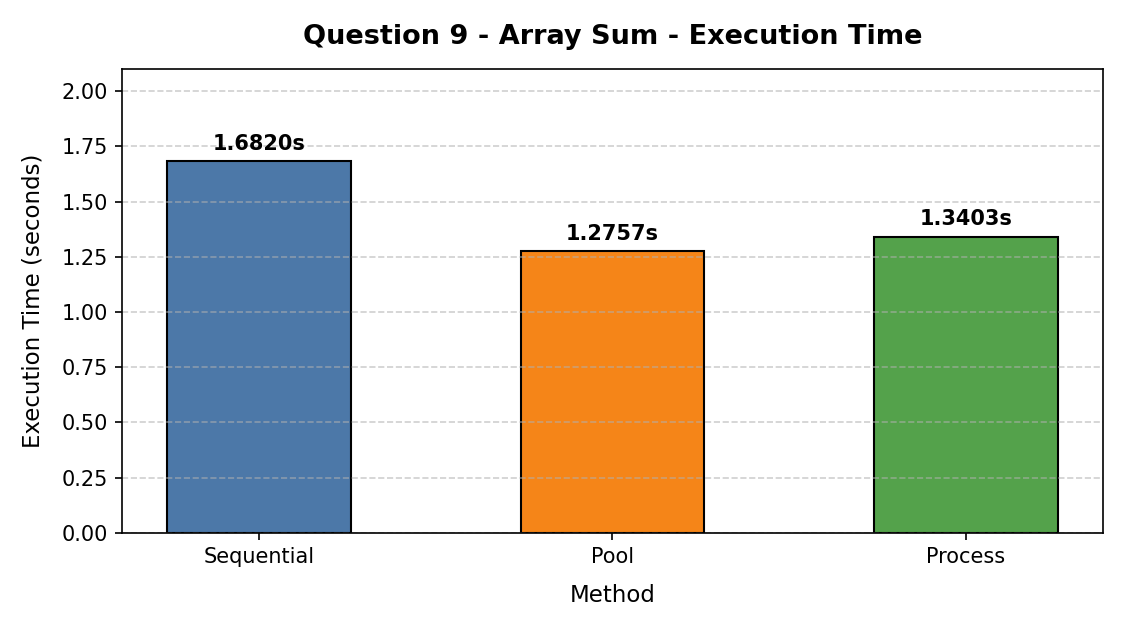

In [2]:
from IPython.display import Image, display
display(Image(filename='09_array_sum_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


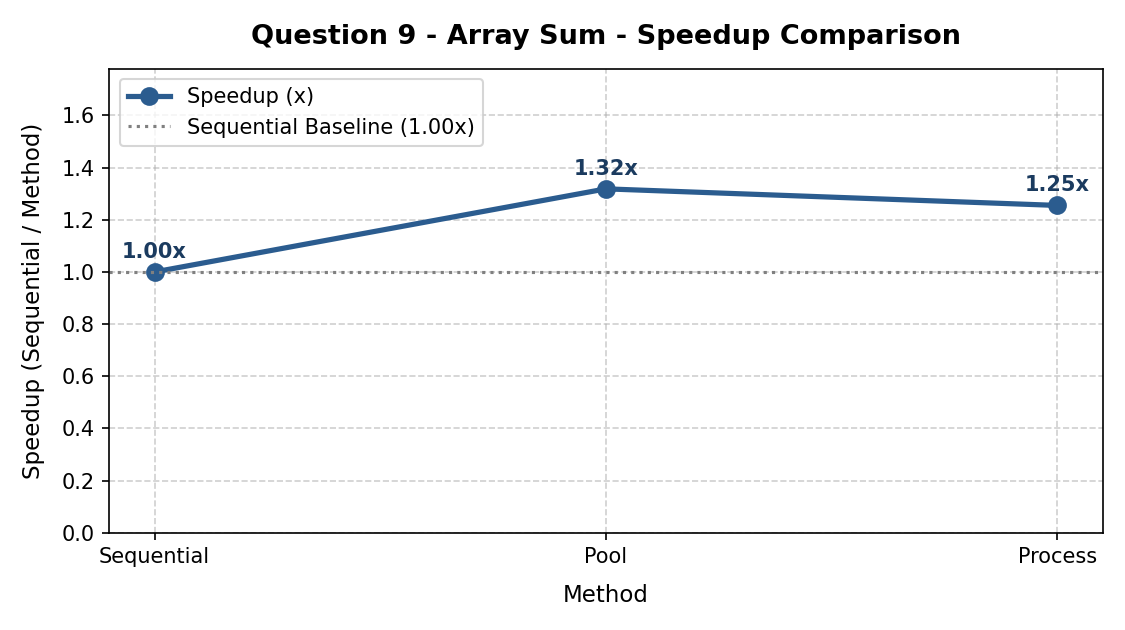

In [3]:
from IPython.display import Image, display
display(Image(filename='09_array_sum_speedup.png'))
